In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

image_folder = "images"

images = []

for filename in os.listdir(image_folder):
    path = os.path.join(image_folder, filename)

    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)

    if img is not None:
        images.append((filename, img))

print("Total images loaded:", len(images))

Total images loaded: 4


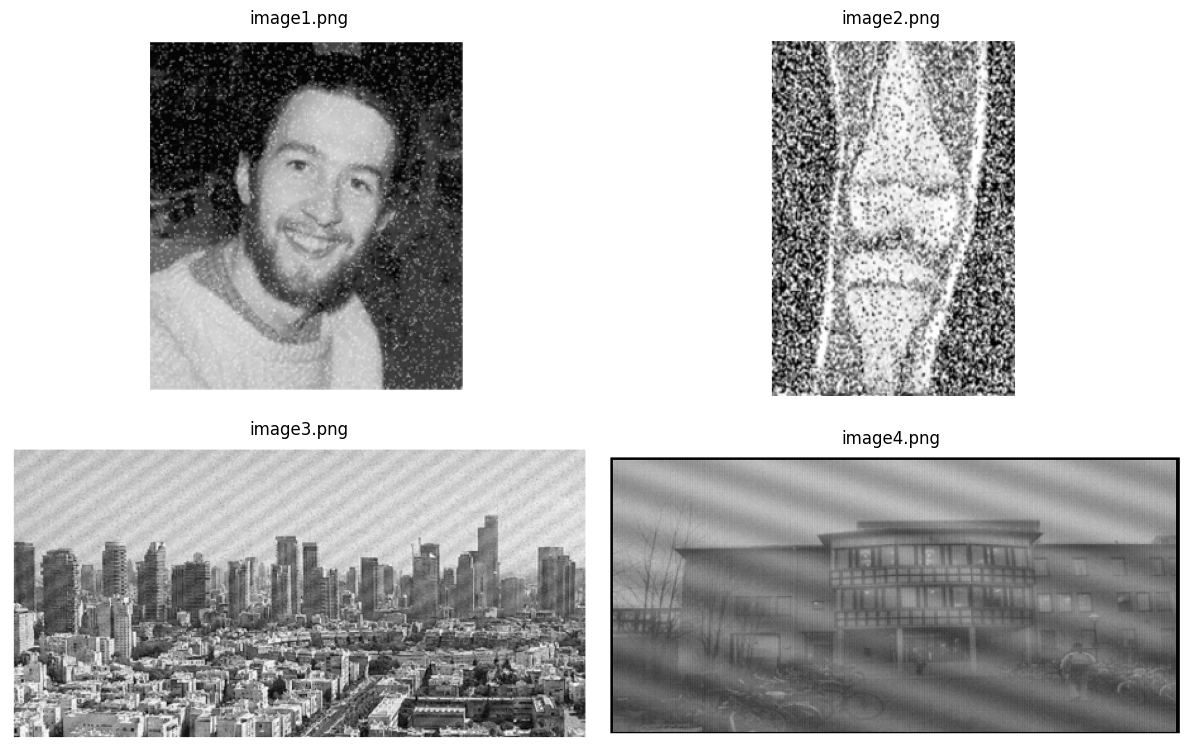

In [2]:
plt.figure(figsize=(12, 8))

for i, (name, img) in enumerate(images):
    plt.subplot(2, 2, i+1)
    plt.imshow(img, cmap='gray')
    plt.title(name)
    plt.axis('off')

plt.tight_layout()
plt.show()

In [3]:
# Step 4: Apply Median Filters

filtered_images = []

for name, img in images:

    # Apply different median filters
    median_3 = cv2.medianBlur(img, 3)
    median_5 = cv2.medianBlur(img, 5)
    median_7 = cv2.medianBlur(img, 7)

    filtered_images.append((name, img, median_3, median_5, median_7))

print("Median filtering completed successfully!")

Median filtering completed successfully!


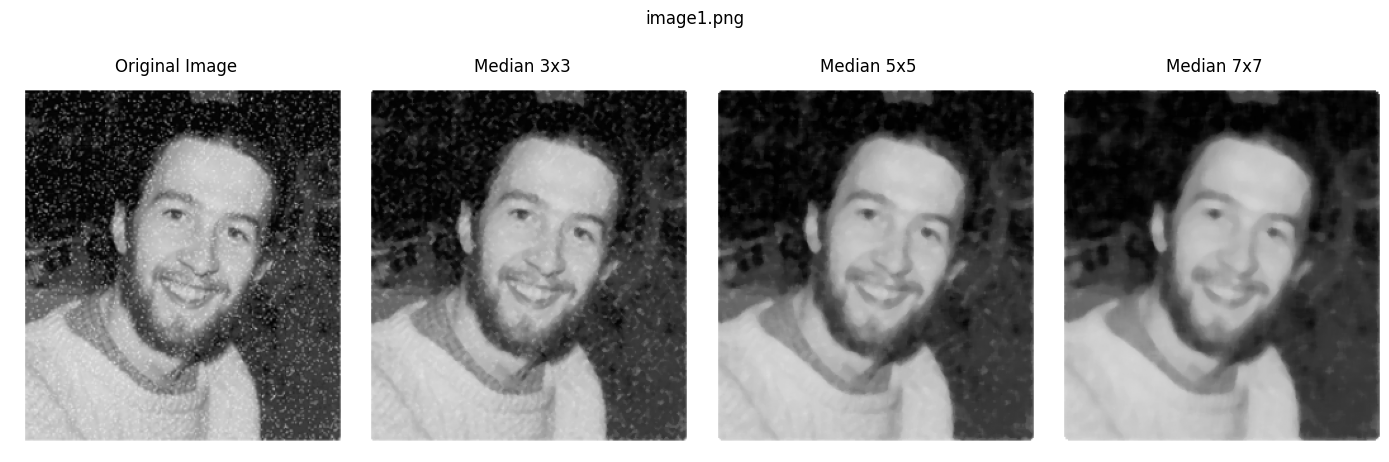

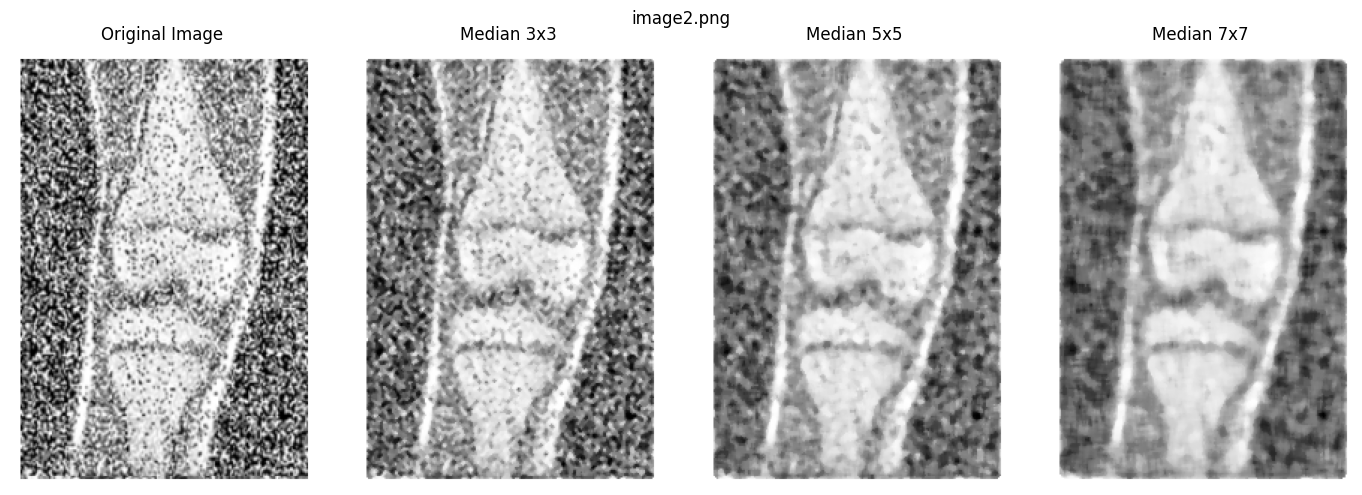

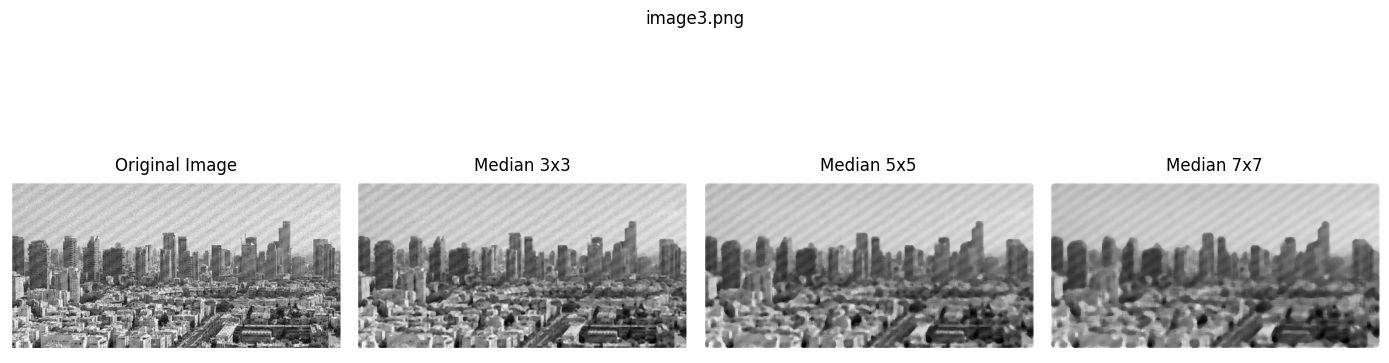

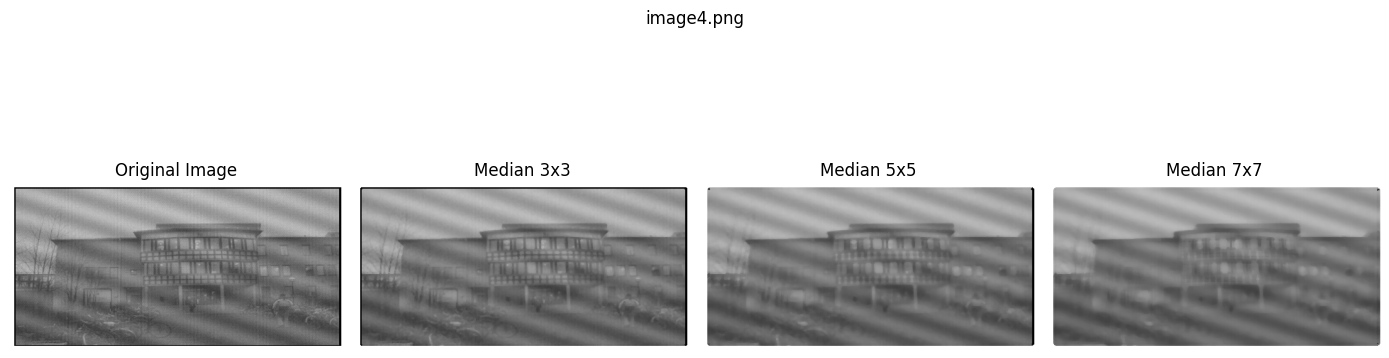

In [4]:
# Display comparison of median filters

for name, original, f3, f5, f7 in filtered_images:

    plt.figure(figsize=(14, 5))

    plt.subplot(1, 4, 1)
    plt.imshow(original, cmap='gray')
    plt.title("Original Image")
    plt.axis('off')

    plt.subplot(1, 4, 2)
    plt.imshow(f3, cmap='gray')
    plt.title("Median 3x3")
    plt.axis('off')

    plt.subplot(1, 4, 3)
    plt.imshow(f5, cmap='gray')
    plt.title("Median 5x5")
    plt.axis('off')

    plt.subplot(1, 4, 4)
    plt.imshow(f7, cmap='gray')
    plt.title("Median 7x7")
    plt.axis('off')

    plt.suptitle(name)
    plt.tight_layout()
    plt.show()

In [5]:
from scipy.ndimage import generic_filter

# Alpha-Trimmed Mean Filter Function
def alpha_trimmed_filter(image, size=3, d=2):

    def trim_mean(values):
        values = np.sort(values)

        # Remove lowest and highest values
        values = values[d//2 : len(values)-d//2]

        return np.mean(values)

    result = generic_filter(
        image.astype(float),
        trim_mean,
        size=size
    )

    return np.clip(result, 0, 255).astype(np.uint8)


print("Alpha-Trimmed Mean Filter function created!")

Alpha-Trimmed Mean Filter function created!


In [ ]:
#Apply Alpha-Trimmed Mean Filter
alpha_filtered_images = []

for name, img in images:

    alpha_3 = alpha_trimmed_filter(img, size=3, d=2)
    alpha_5 = alpha_trimmed_filter(img, size=5, d=4)

    alpha_filtered_images.append((name, img, alpha_3, alpha_5))

print("Alpha-Trimmed Mean Filtering completed!")

Alpha-Trimmed Mean Filtering completed!


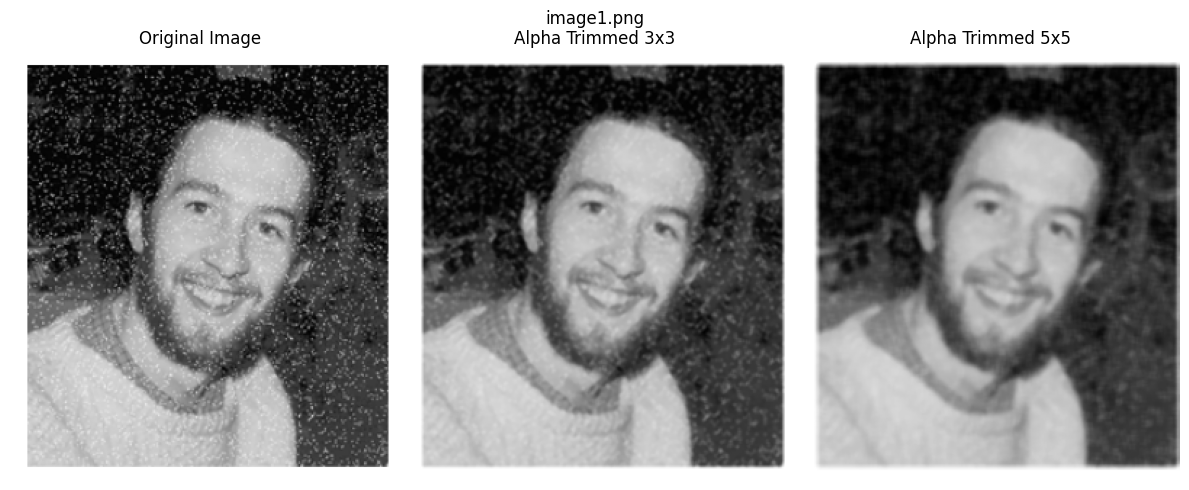

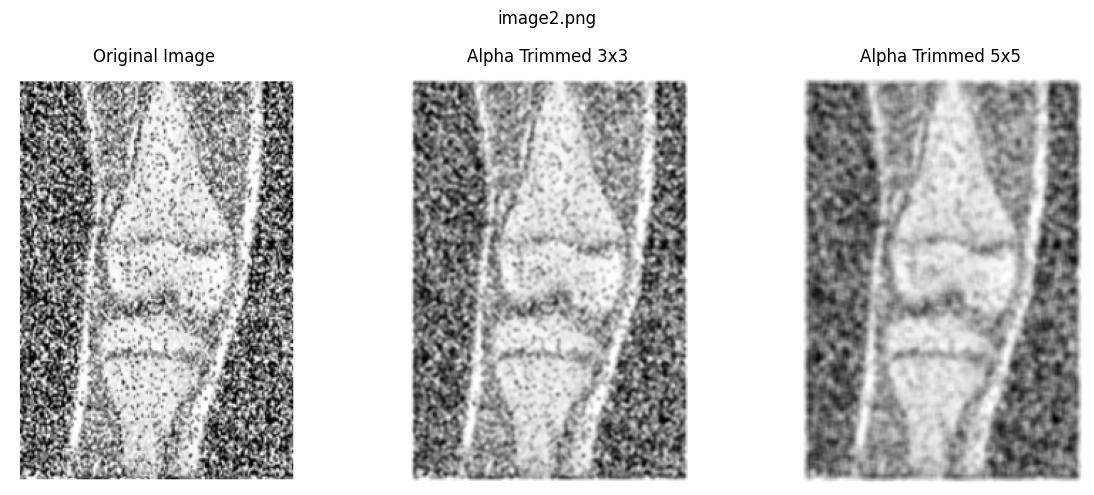

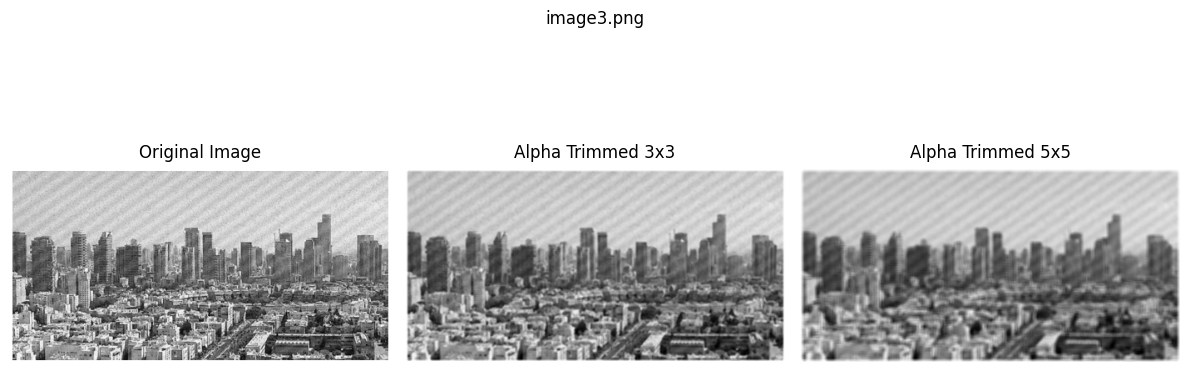

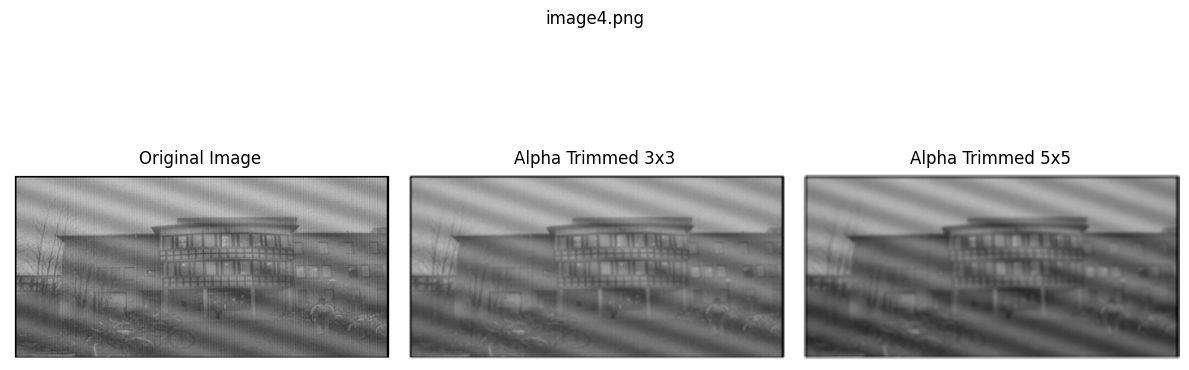

In [ ]:
#Display comparison
for name, original, alpha3, alpha5 in alpha_filtered_images:

    plt.figure(figsize=(12, 5))

    plt.subplot(1, 3, 1)
    plt.imshow(original, cmap='gray')
    plt.title("Original Image")
    plt.axis('off')

    plt.subplot(1, 3, 2)
    plt.imshow(alpha3, cmap='gray')
    plt.title("Alpha Trimmed 3x3")
    plt.axis('off')

    plt.subplot(1, 3, 3)
    plt.imshow(alpha5, cmap='gray')
    plt.title("Alpha Trimmed 5x5")
    plt.axis('off')

    plt.suptitle(name)
    plt.tight_layout()
    plt.show()